# E-commerce Operations & Delivery Performance
**Question:** Is the business growing, are we hitting our delivery promises, and what does missing them cost us in customer satisfaction?

**Data:** [Olist Brazilian E-Commerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): ~100K real, anonymized marketplace orders (2016–2018) across 8 related tables covering orders, line items, payments, reviews, products, sellers and customers.

**Tools:** SQL (DuckDB): JOINs across 4+ tables, CTEs, `RANK`, window percentages, `HAVING`, date math · Python: pandas, matplotlib

This analysis treats the business like a set of operational KPIs (on-time delivery rate as an SLA, seller scorecards, regional performance), which is the same kind of tracking used in business and project-management analytics.

## Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DB = "data/ecommerce.duckdb"   # built by setup_data.py
con = duckdb.connect(DB, read_only=True)

def q(sql):
    """Run a SQL query and return a pandas DataFrame."""
    return con.sql(sql).df()

# Chart style: one blue for single-series charts, quiet axes and grid
BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe8",
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": INK, "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.set_option("display.max_columns", 20)
q("SHOW TABLES")

,name
0,category_translation
1,customers
2,order_items
3,order_payments
4,order_reviews
5,orders
6,products
7,sellers


## 1. Monthly orders and revenue
How did order volume and revenue grow? (excludes the partial first/last months)

In [2]:
df = q("""
SELECT date_trunc('month', o.order_purchase_timestamp)::DATE AS month,
       COUNT(DISTINCT o.order_id)                           AS orders,
       ROUND(SUM(oi.price + oi.freight_value), 0)           AS revenue
FROM orders o
JOIN order_items oi USING (order_id)
WHERE o.order_status = 'delivered'
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
GROUP BY month
ORDER BY month
""")
df

,month,orders,revenue
0,2017-01-01,750,127482.0
1,2017-02-01,1653,271239.0
2,2017-03-01,2546,414331.0
3,2017-04-01,2303,390812.0
4,2017-05-01,3546,566851.0
5,2017-06-01,3135,490050.0
6,2017-07-01,3872,566299.0
7,2017-08-01,4193,645832.0
8,2017-09-01,4150,701077.0
9,2017-10-01,4478,751117.0


**Finding:** Monthly orders grew ~8x from January 2017 to the 2018 plateau of ~6–7K orders, with a Black Friday spike in November 2017.

## 2. On-time delivery rate by month (SLA tracking)
What % of orders arrived by the promised date, and how did that change over time?

In [3]:
df = q("""
SELECT date_trunc('month', order_purchase_timestamp)::DATE AS month,
       COUNT(*)                                                  AS delivered_orders,
       ROUND(100.0 * AVG(CASE WHEN order_delivered_customer_date <= order_estimated_delivery_date
                              THEN 1 ELSE 0 END), 1)            AS on_time_pct,
       ROUND(AVG(date_diff('day', order_purchase_timestamp, order_delivered_customer_date)), 1) AS avg_days_to_deliver
FROM orders
WHERE order_status = 'delivered'
  AND order_delivered_customer_date IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-09-01'
GROUP BY month
ORDER BY month
""")
df

,month,delivered_orders,on_time_pct,avg_days_to_deliver
0,2017-01-01,750,96.9,12.8
1,2017-02-01,1653,96.8,13.3
2,2017-03-01,2546,94.4,13.0
3,2017-04-01,2303,92.1,15.0
4,2017-05-01,3545,96.4,11.4
5,2017-06-01,3135,96.1,12.0
6,2017-07-01,3872,96.6,11.5
7,2017-08-01,4193,96.7,11.0
8,2017-09-01,4150,94.8,11.7
9,2017-10-01,4478,94.7,11.7


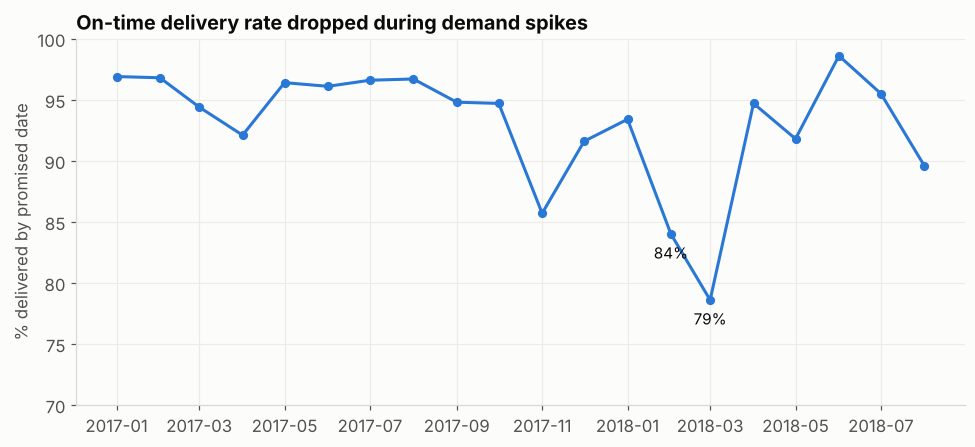

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(df["month"], df["on_time_pct"], color=BLUE, linewidth=2, marker="o", markersize=5)
low = df.nsmallest(2, "on_time_pct")
for _, r in low.iterrows():
    ax.annotate(f"{r.on_time_pct:.0f}%", (r.month, r.on_time_pct), textcoords="offset points", xytext=(0, -16), ha="center", color=INK, fontsize=10)
ax.set_title("On-time delivery rate dropped during demand spikes")
ax.set_ylabel("% delivered by promised date"); ax.set_ylim(70, 100)
plt.tight_layout(); plt.savefig("images/on_time_rate.png", dpi=150); plt.show()

**Finding:** On-time delivery is usually 92–97%, but it fell to **86% during the November 2017 Black Friday spike and to 84% / 79% in February / March 2018**. Operations didn't keep up when volume jumped.

## 3. Does late delivery hurt customer satisfaction?
Average review score by how late the order arrived.

In [5]:
df = q("""
WITH d AS (
    SELECT o.order_id,
           date_diff('day', o.order_estimated_delivery_date, o.order_delivered_customer_date) AS days_late,
           r.review_score
    FROM orders o
    JOIN order_reviews r USING (order_id)
    WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
)
SELECT CASE WHEN days_late <= 0  THEN '1 - On time or early'
            WHEN days_late <= 3  THEN '2 - 1-3 days late'
            WHEN days_late <= 7  THEN '3 - 4-7 days late'
            ELSE                      '4 - 8+ days late' END AS delivery_bucket,
       COUNT(*)                                            AS orders,
       ROUND(AVG(review_score), 2)                         AS avg_review,
       ROUND(100.0 * AVG(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END), 1) AS pct_1_or_2_star
FROM d
GROUP BY delivery_bucket
ORDER BY delivery_bucket
""")
df

,delivery_bucket,orders,avg_review,pct_1_or_2_star
0,1 - On time or early,89944,4.29,9.3
1,2 - 1-3 days late,1856,3.29,32.2
2,3 - 4-7 days late,1756,2.10,67.7
3,4 - 8+ days late,2797,1.70,79.2


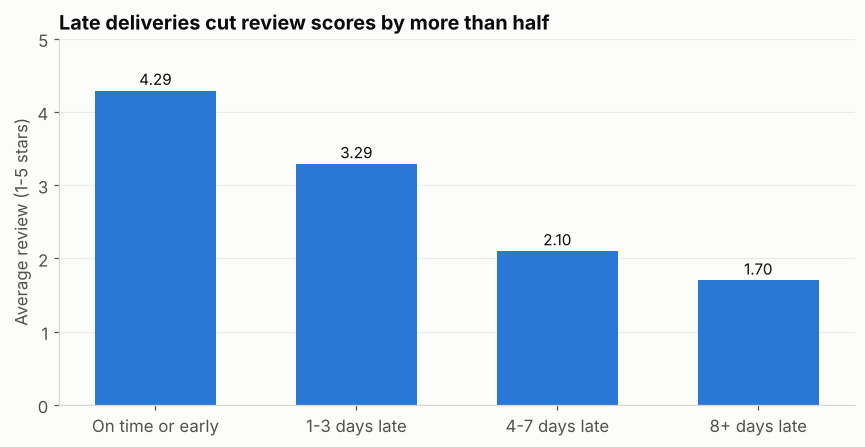

In [6]:
labels = [b.split(" - ")[1] for b in df["delivery_bucket"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(labels, df["avg_review"], color=BLUE, width=0.6)
for x, v in enumerate(df["avg_review"]):
    ax.text(x, v + 0.08, f"{v:.2f}", ha="center", color=INK, fontsize=10)
ax.set_title("Late deliveries cut review scores by more than half")
ax.set_ylabel("Average review (1-5 stars)"); ax.set_ylim(0, 5); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/late_delivery_reviews.png", dpi=150); plt.show()

**Finding:** **This is the headline finding.** On-time orders average 4.29 stars. Orders 8+ days late average 1.70, and 79% of them get a 1- or 2-star review. Delivery reliability is a major driver of customer satisfaction in this data.

## 4. Revenue by product category
Top 10 categories by revenue, with average order value and review score.

In [7]:
df = q("""
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       COUNT(DISTINCT oi.order_id)       AS orders,
       ROUND(SUM(oi.price), 0)           AS revenue,
       ROUND(AVG(oi.price), 2)           AS avg_item_price,
       ROUND(AVG(r.review_score), 2)     AS avg_review
FROM order_items oi
JOIN products p                    USING (product_id)
LEFT JOIN category_translation t   USING (product_category_name)
LEFT JOIN order_reviews r          USING (order_id)
GROUP BY category
ORDER BY revenue DESC
LIMIT 10
""")
df

,category,orders,revenue,avg_item_price,avg_review
0,health_beauty,8836,1263139.0,129.86,4.14
1,watches_gifts,5624,1206075.0,200.98,4.02
2,bed_bath_table,9417,1050937.0,93.25,3.90
3,sports_leisure,7720,993657.0,114.21,4.11
4,computers_accessories,6689,919641.0,116.50,3.93
5,furniture_decor,6449,736282.0,87.50,3.90
6,cool_stuff,3632,637259.0,167.44,4.15
7,housewares,5884,634543.0,90.79,4.06
8,auto,3897,594363.0,139.65,4.07
9,garden_tools,3518,486432.0,111.54,4.04


**Finding:** Health & beauty and watches/gifts lead revenue. Watches/gifts gets there with the highest average item price (~R$201).

## 5. Seller scorecard
Rank sellers (50+ orders) by revenue and flag the ones with poor delivery or reviews.

In [8]:
df = q("""
WITH seller_orders AS (
    SELECT oi.seller_id, o.order_id, SUM(oi.price) AS order_revenue,
           MAX(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END) AS late,
           MAX(r.review_score) AS review_score
    FROM order_items oi
    JOIN orders o USING (order_id)
    LEFT JOIN order_reviews r USING (order_id)
    WHERE o.order_status = 'delivered'
    GROUP BY oi.seller_id, o.order_id
)
SELECT RANK() OVER (ORDER BY SUM(order_revenue) DESC) AS revenue_rank,
       seller_id,
       COUNT(*)                          AS orders,
       ROUND(SUM(order_revenue), 0)      AS revenue,
       ROUND(100.0 * AVG(late), 1)       AS late_pct,
       ROUND(AVG(review_score), 2)       AS avg_review,
       CASE WHEN AVG(late) > 0.12 OR AVG(review_score) < 3.8 THEN 'REVIEW' ELSE 'OK' END AS flag
FROM seller_orders
GROUP BY seller_id
HAVING COUNT(*) >= 50
ORDER BY revenue_rank
LIMIT 15
""")
df

,revenue_rank,seller_id,orders,revenue,late_pct,avg_review,flag
0,1,4869f7a5dfa277a7dca6462dcf3b52b2,1124,226988.0,11.6,4.15,OK
1,2,53243585a1d6dc2643021fd1853d8905,348,217940.0,4.3,4.19,OK
2,3,4a3ca9315b744ce9f8e9374361493884,1772,199408.0,11.0,3.86,OK
3,4,fa1c13f2614d7b5c4749cbc52fecda94,578,190917.0,10.2,4.37,OK
4,5,7c67e1448b00f6e969d365cea6b010ab,973,188064.0,10.1,3.50,REVIEW
5,6,7e93a43ef30c4f03f38b393420bc753a,319,165981.0,5.6,4.36,OK
6,7,da8622b14eb17ae2831f4ac5b9dab84a,1311,162304.0,7.6,4.18,OK
7,8,7a67c85e85bb2ce8582c35f2203ad736,1145,140239.0,5.9,4.28,OK
8,9,1025f0e2d44d7041d6cf58b6550e0bfa,910,139720.0,10.1,4.02,OK
9,10,955fee9216a65b617aa5c0531780ce60,1261,131907.0,7.8,4.20,OK


**Finding:** A simple seller scorecard: rank by revenue, flag anyone above a 12% late rate or below a 3.8-star average. The #5 seller by revenue gets flagged for a 3.50 average review, which makes it a priority for an account-management conversation.

## 6. Customer retention
What share of customers ever place a second order?

In [9]:
df = q("""
WITH per_customer AS (
    SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS orders
    FROM orders o
    JOIN customers c USING (customer_id)
    WHERE o.order_status = 'delivered'
    GROUP BY c.customer_unique_id
)
SELECT COUNT(*)                                             AS customers,
       COUNT(*) FILTER (WHERE orders > 1)                   AS repeat_customers,
       ROUND(100.0 * COUNT(*) FILTER (WHERE orders > 1) / COUNT(*), 2) AS repeat_rate_pct
FROM per_customer
""")
df

,customers,repeat_customers,repeat_rate_pct
0,93358,2801,3.0


**Finding:** **Only 3% of customers ever order a second time.** The business runs almost entirely on new-customer acquisition, which makes retention the clearest growth opportunity.

## 7. Delivery performance by state
Which regions wait longest? (states with 500+ orders)

In [10]:
df = q("""
SELECT c.customer_state                                                        AS state,
       COUNT(*)                                                                AS orders,
       ROUND(AVG(date_diff('day', o.order_purchase_timestamp, o.order_delivered_customer_date)), 1) AS avg_days,
       ROUND(100.0 * AVG(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date THEN 1 ELSE 0 END), 1) AS late_pct
FROM orders o
JOIN customers c USING (customer_id)
WHERE o.order_status = 'delivered' AND o.order_delivered_customer_date IS NOT NULL
GROUP BY state
HAVING COUNT(*) >= 500
ORDER BY avg_days DESC
""")
df

,state,orders,avg_days,late_pct
0,PA,946,23.7,12.4
1,MA,717,21.5,19.7
2,CE,1279,21.2,15.3
3,PB,517,20.4,11.0
4,BA,3256,19.3,14.0
5,PE,1593,18.4,10.8
6,MT,886,18.0,6.8
7,ES,1995,15.7,12.2
8,GO,1957,15.5,8.2
9,MS,701,15.5,11.6


**Finding:** São Paulo (SP) customers get orders in ~9 days. Northern and northeastern states wait 20+ days and see 2–3x the late rate, which points to a logistics/fulfillment-network gap rather than a seller problem.

## 8. Payment methods
How do customers pay, and do installment plans raise order value?

In [11]:
df = q("""
SELECT payment_type,
       COUNT(DISTINCT order_id)               AS orders,
       ROUND(100.0 * COUNT(DISTINCT order_id) / SUM(COUNT(DISTINCT order_id)) OVER (), 1) AS pct_orders,
       ROUND(AVG(payment_value), 2)           AS avg_payment,
       ROUND(AVG(payment_installments), 1)    AS avg_installments
FROM order_payments
WHERE payment_type <> 'not_defined'
GROUP BY payment_type
ORDER BY orders DESC
""")
df

,payment_type,orders,pct_orders,avg_payment,avg_installments
0,credit_card,76505,75.2,163.32,3.5
1,boleto,19784,19.5,145.03,1.0
2,voucher,3866,3.8,65.70,1.0
3,debit_card,1528,1.5,142.57,1.0


**Finding:** Credit card is 75% of orders, averaging 3.5 installments. Boleto (a Brazilian cash/bank-slip method) is the main alternative at ~20%.

## Python cross-check: repeat-customer rate in pandas
Re-computing the repeat-customer rate with a pandas merge + groupby. It should match the SQL result.

In [12]:
orders = q("SELECT order_id, customer_id FROM orders WHERE order_status = 'delivered'")
customers = q("SELECT customer_id, customer_unique_id FROM customers")
per_cust = orders.merge(customers, on="customer_id").groupby("customer_unique_id")["order_id"].nunique()
print(f"Customers: {len(per_cust):,} | Repeat: {(per_cust > 1).sum():,} | Rate: {100 * (per_cust > 1).mean():.2f}%")

Customers: 93,358 | Repeat: 2,801 | Rate: 3.00%
